# V2 kayitli sonuclar — salt okuma; completed fiziksel kabul degildir.


Grup: completed | completed fiziksel kabul degildir


,experiment_id,scenario_id,state,controls,calculation,k,MC_standard_error,duration_s,fields_npz,summary_json,physical_acceptance,statistical_convergence
0,V2-STAGE_256_OGRENCI_04-0001,a8a186e90182046cded9f433e6fd6854e26e73349d481c...,completed,{'u235_enrichment_wt_percent': 2.2464887907697...,"{'particles_per_generation': 80000, 'batches':...",1.050850,0.000191,5914.728212,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
1,V2-STAGE_256_OGRENCI_04-0002,de3f180bd755e17a38bfce5d3aa86fc0e228a365fbbeed...,completed,{'u235_enrichment_wt_percent': 1.8714887907697...,"{'particles_per_generation': 80000, 'batches':...",0.916009,0.000160,5493.359124,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
2,V2-STAGE_256_OGRENCI_04-0003,a8dcefcfa92726fbdd3245358b53cac853f67b7e36b503...,completed,{'u235_enrichment_wt_percent': 2.6214887907697...,"{'particles_per_generation': 80000, 'batches':...",0.984472,0.000192,5232.367018,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
3,V2-STAGE_256_OGRENCI_04-0004,95b81ebae19aa189bc059ea3a3308d0fbd64e691874b1a...,completed,{'u235_enrichment_wt_percent': 1.6839887907697...,"{'particles_per_generation': 80000, 'batches':...",0.714512,0.000157,5796.096323,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
4,V2-STAGE_256_OGRENCI_04-0005,d7c06a0a999222df00239f9ab717287e259b3cf5e7875b...,completed,{'u235_enrichment_wt_percent': 2.4339887907697...,"{'particles_per_generation': 80000, 'batches':...",1.270190,0.000185,6031.830188,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
5,V2-STAGE_256_OGRENCI_04-0006,c2619d1a57e4a0ca0ae94d3375483122c4dfe92fa0b095...,completed,{'u235_enrichment_wt_percent': 2.0589887907697...,"{'particles_per_generation': 80000, 'batches':...",1.204953,0.000185,5746.905486,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
6,V2-STAGE_256_OGRENCI_04-0007,510e581b4509d2cd982838df19934759299df905d3ca30...,completed,{'u235_enrichment_wt_percent': 2.8089887907697...,"{'particles_per_generation': 80000, 'batches':...",1.278385,0.000192,1008.034099,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
7,V2-STAGE_256_OGRENCI_04-0008,fc0858cd9239d7faca6624e5b5836997245a51fb70e6df...,completed,{'u235_enrichment_wt_percent': 2.9496137907697...,"{'particles_per_generation': 80000, 'batches':...",1.275499,0.000195,987.484586,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
8,V2-STAGE_256_OGRENCI_04-0009,0594ce8ea9aeab07ef6fb7dde99e13b43d28bc6b99aaee...,completed,{'u235_enrichment_wt_percent': 2.1996137907697...,"{'particles_per_generation': 80000, 'batches':...",1.170751,0.000192,1019.878232,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
9,V2-STAGE_256_OGRENCI_04-0010,24bad42745c270429ffad06a21aeba7086c9749bd12e10...,completed,{'u235_enrichment_wt_percent': 1.8246137907697...,"{'particles_per_generation': 80000, 'batches':...",1.091770,0.000177,1019.171232,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required


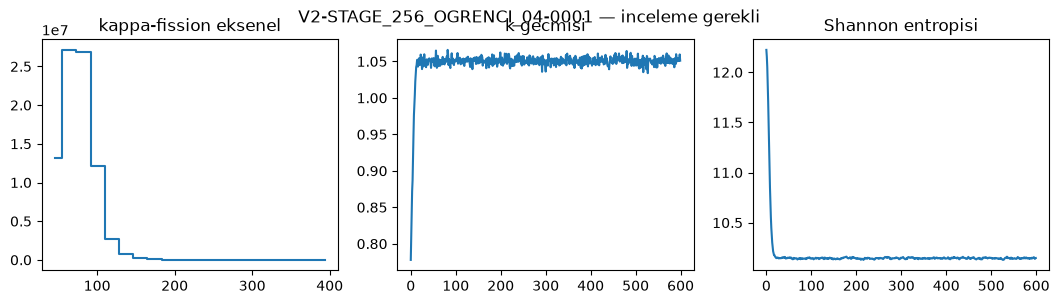

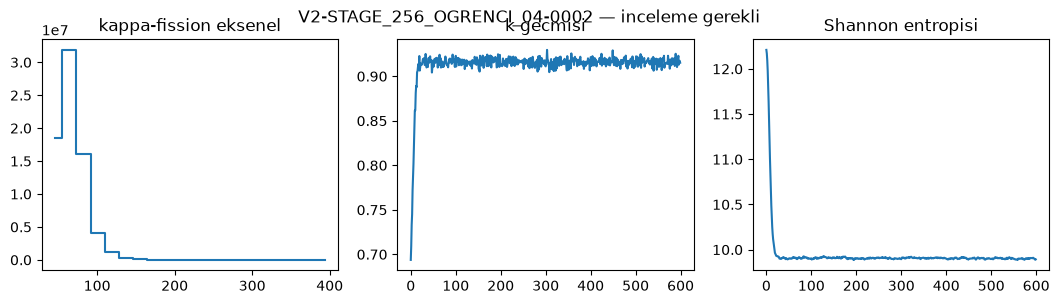

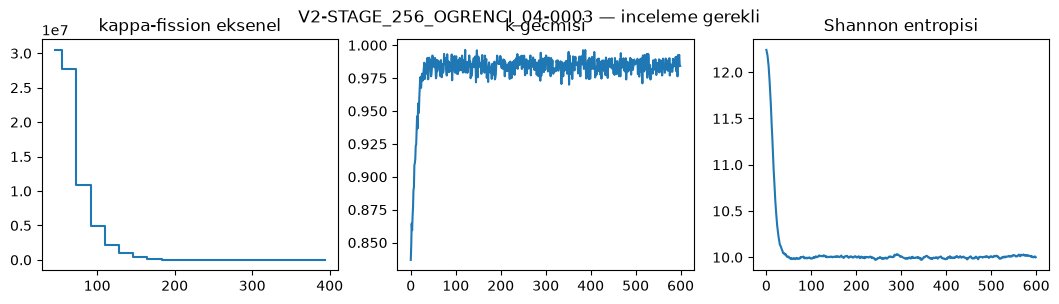

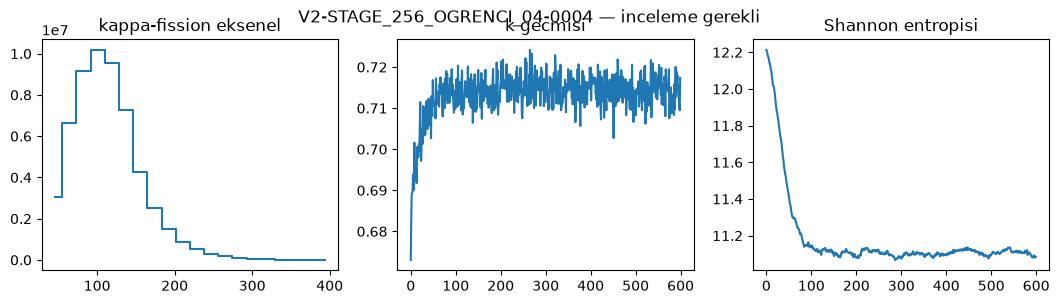

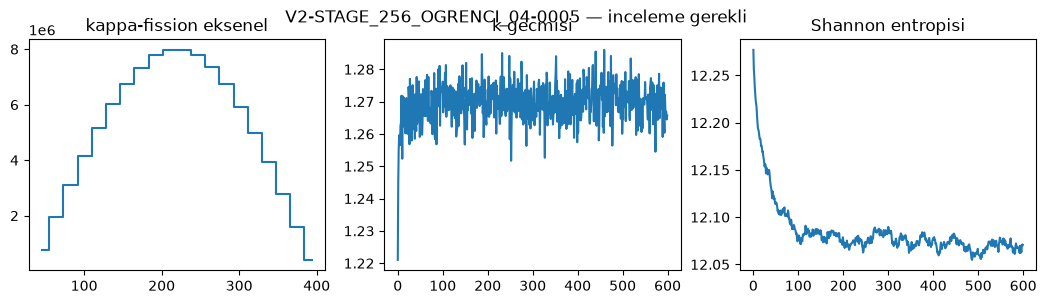

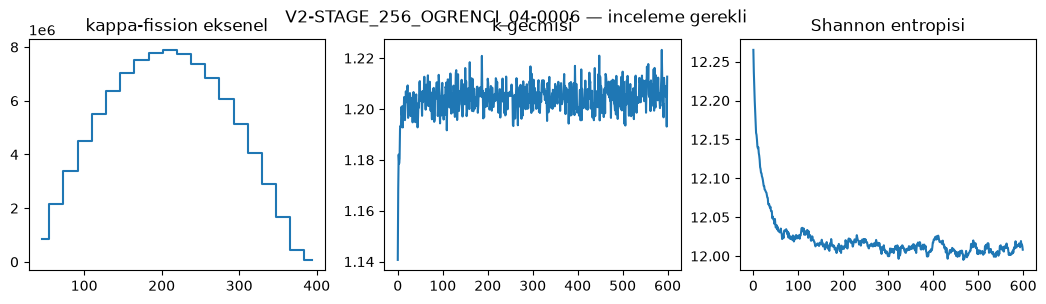

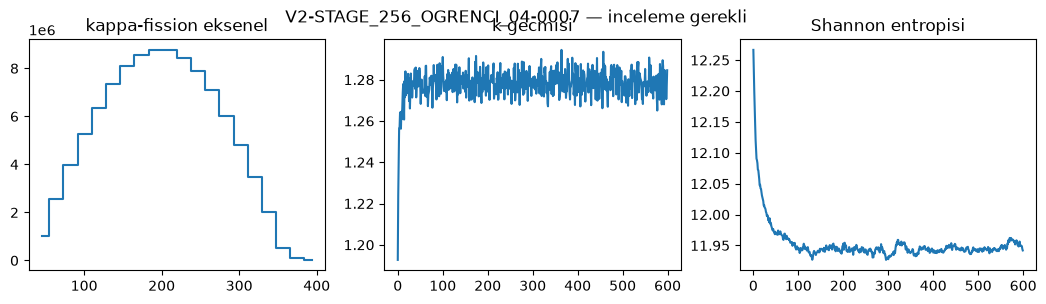

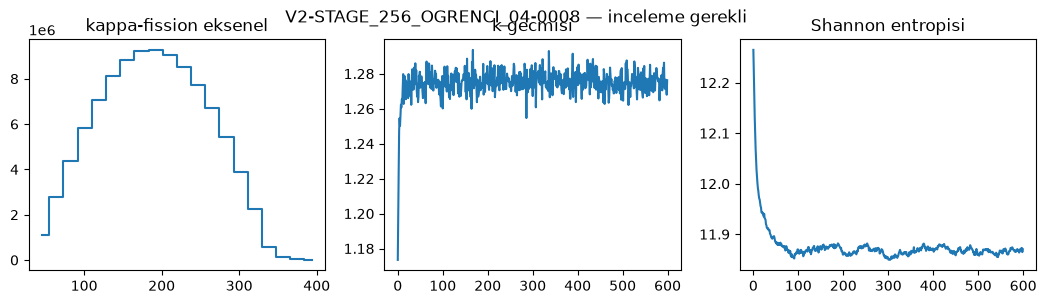

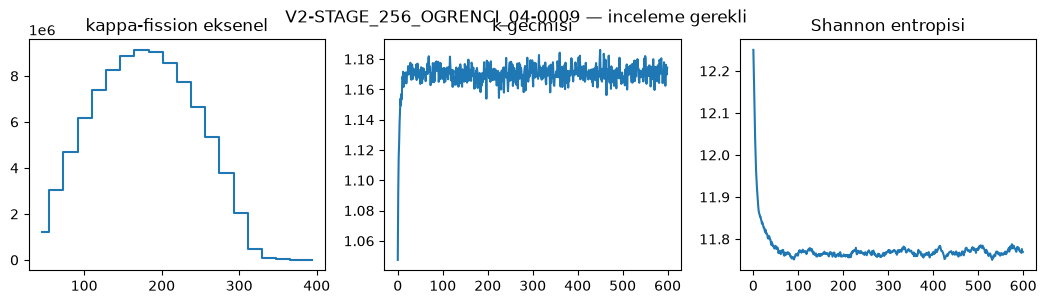

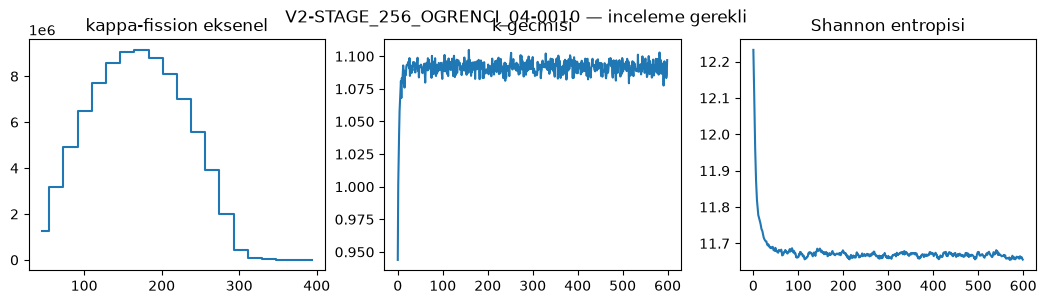

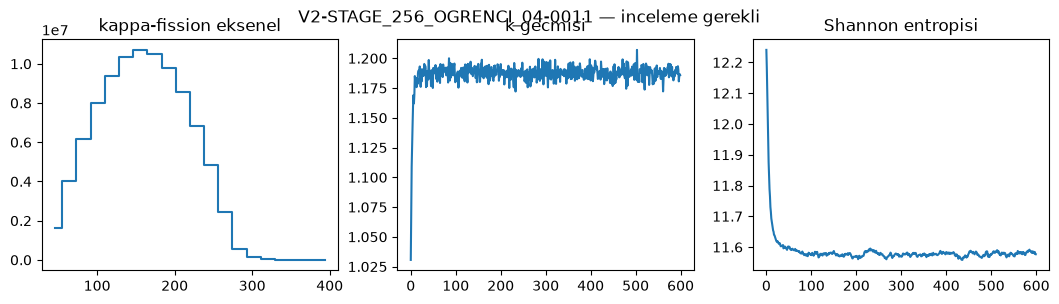

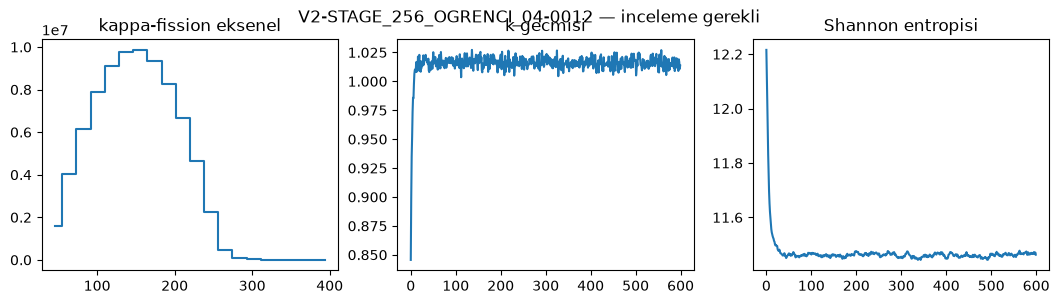

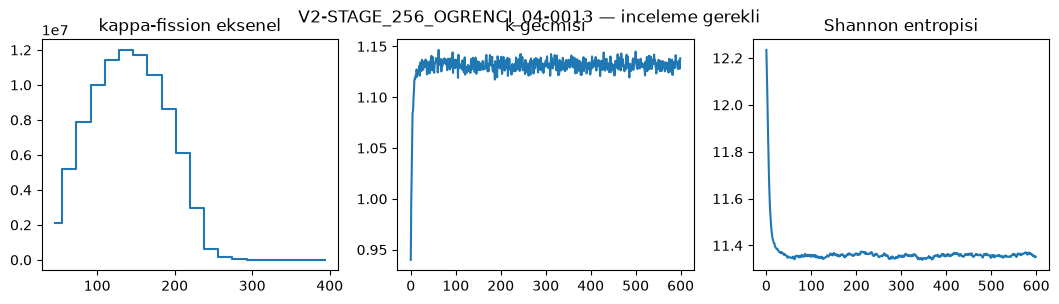

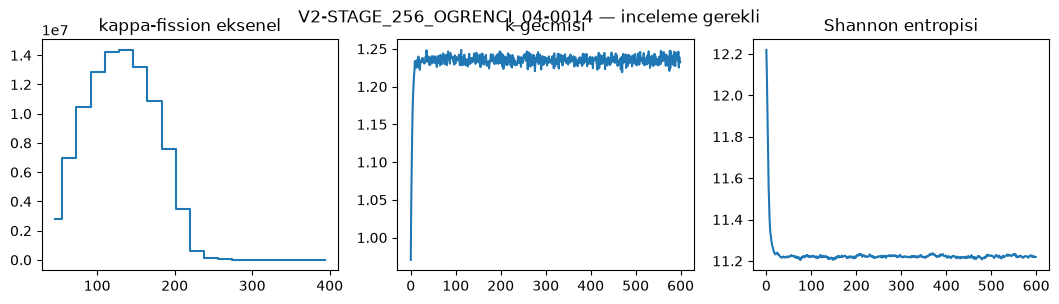

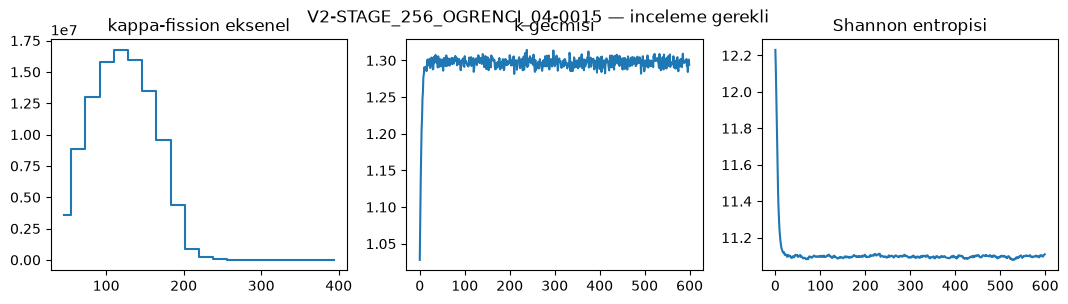

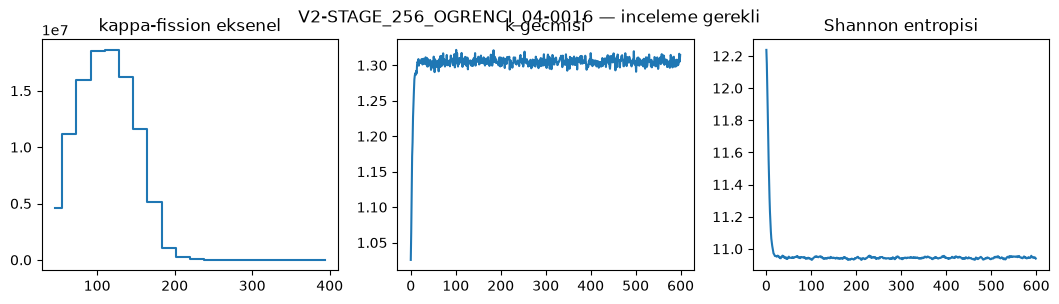

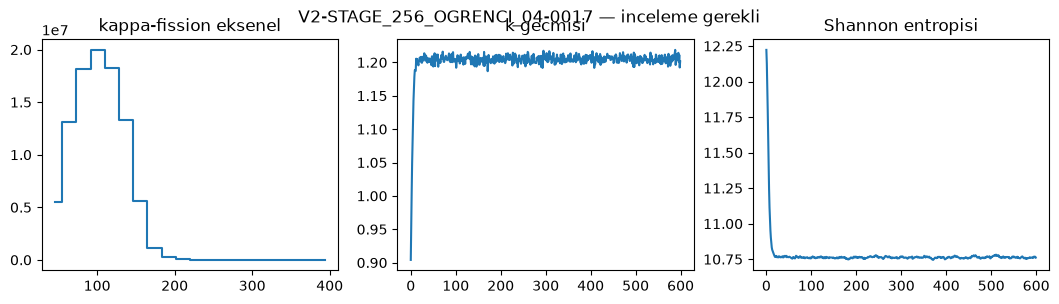

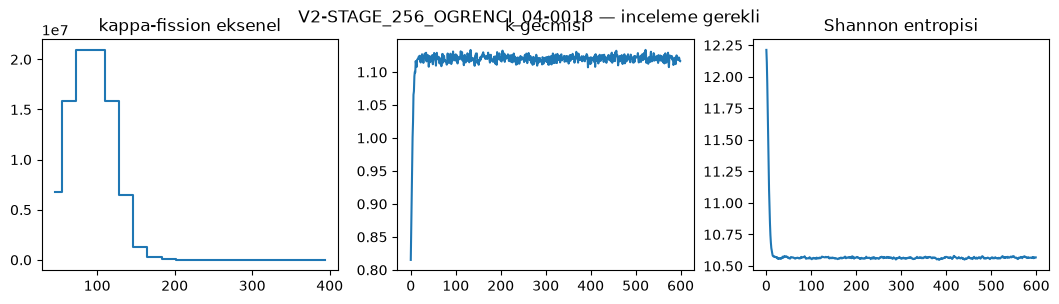

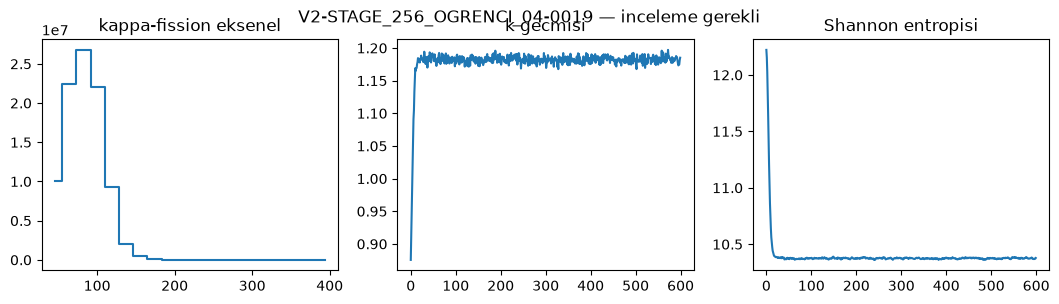

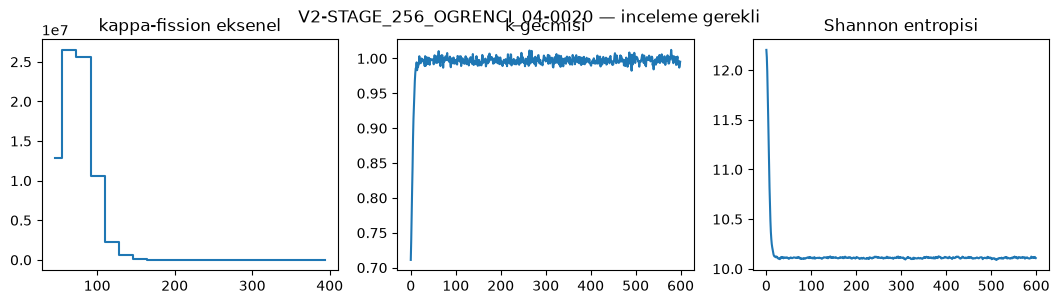

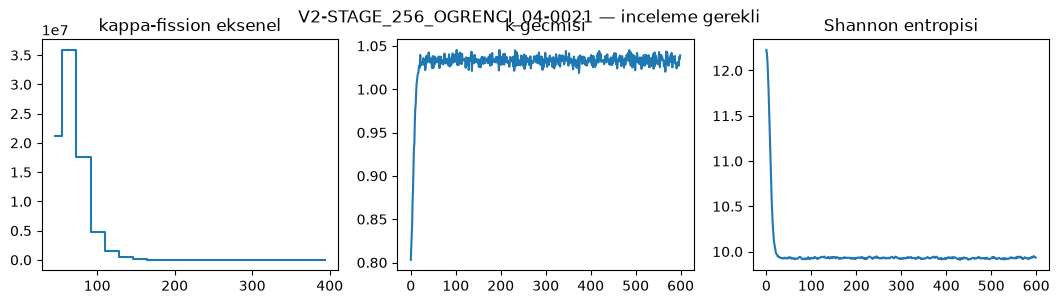

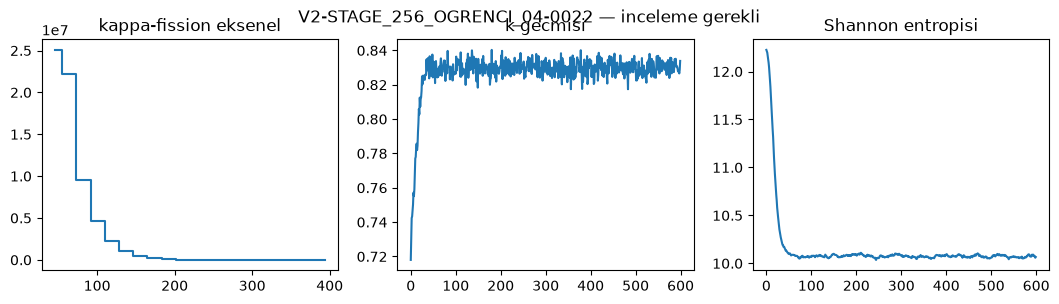

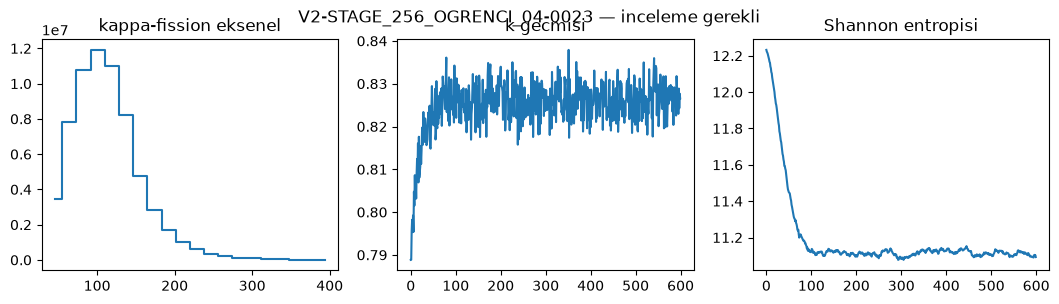

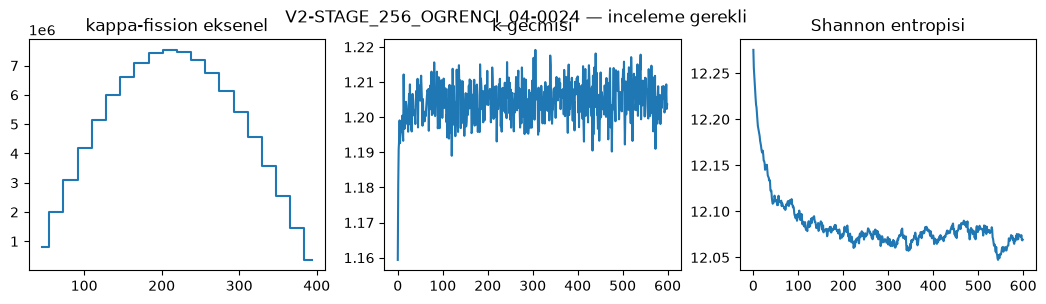

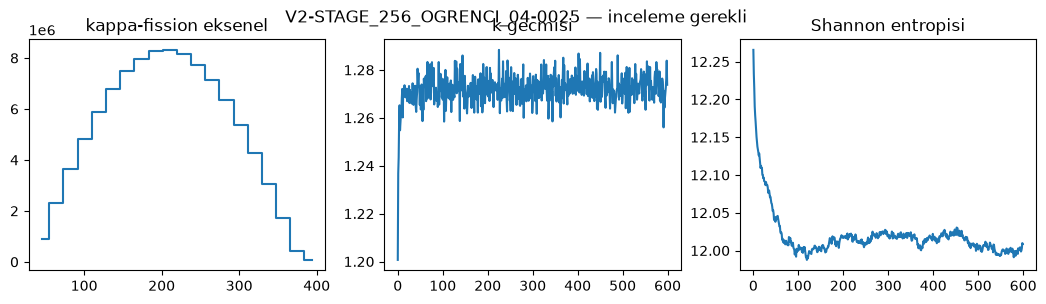

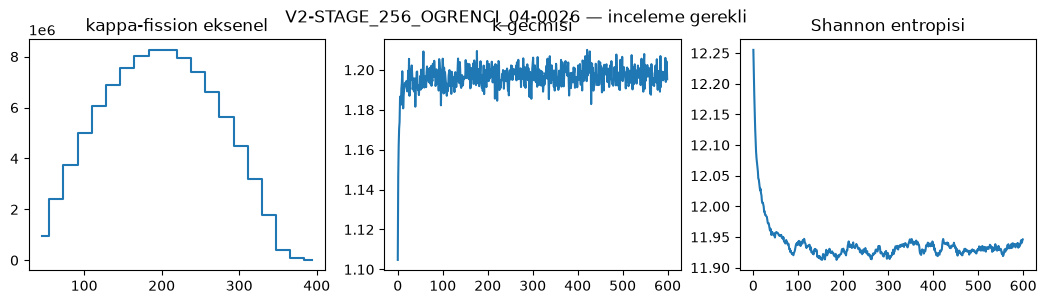

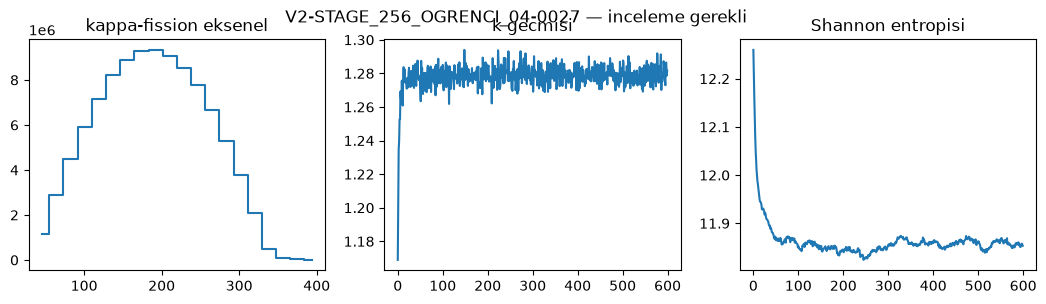

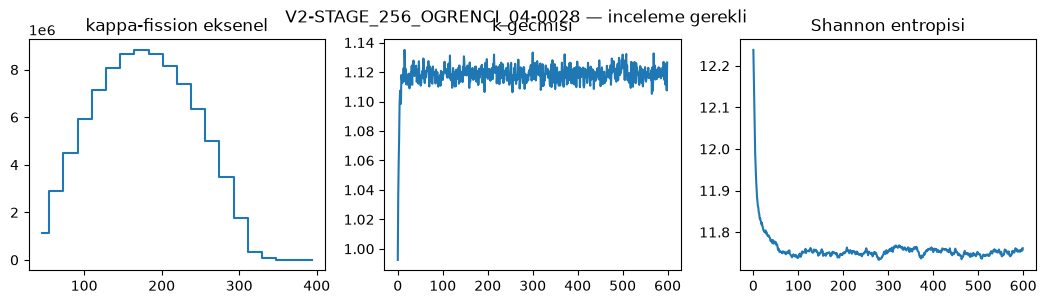

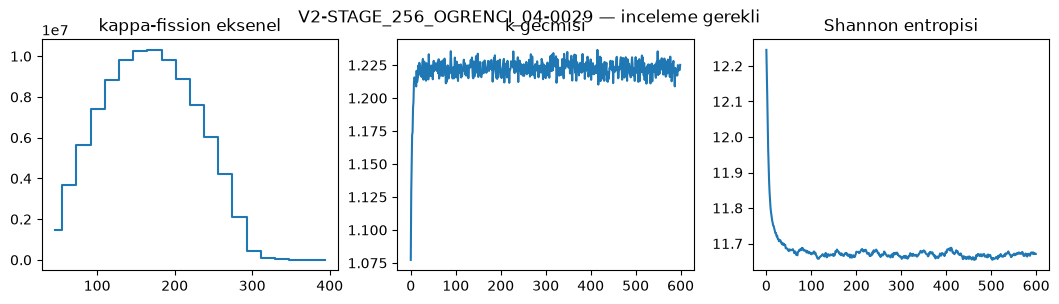

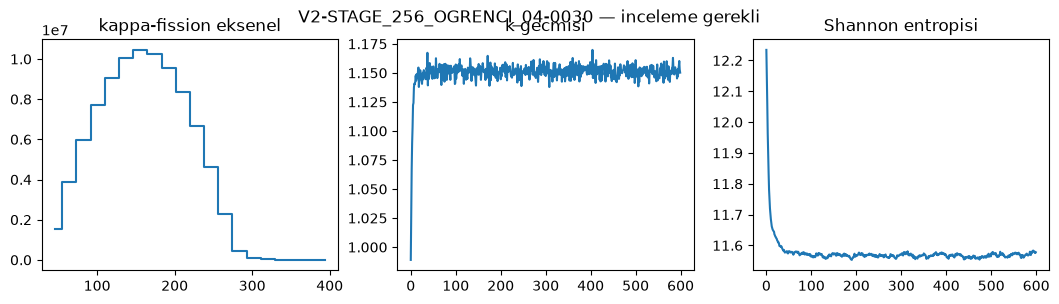

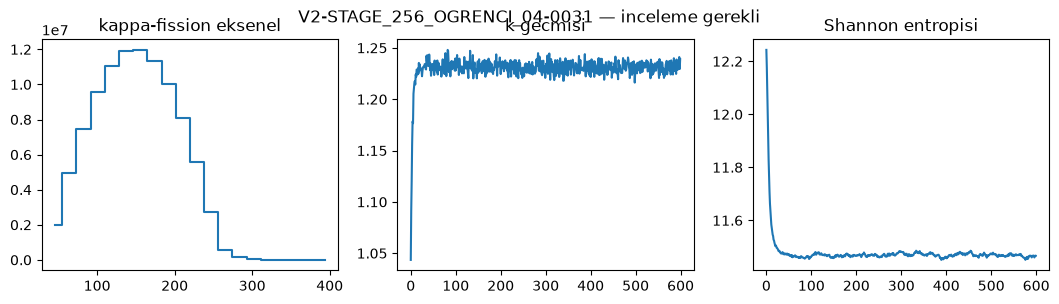

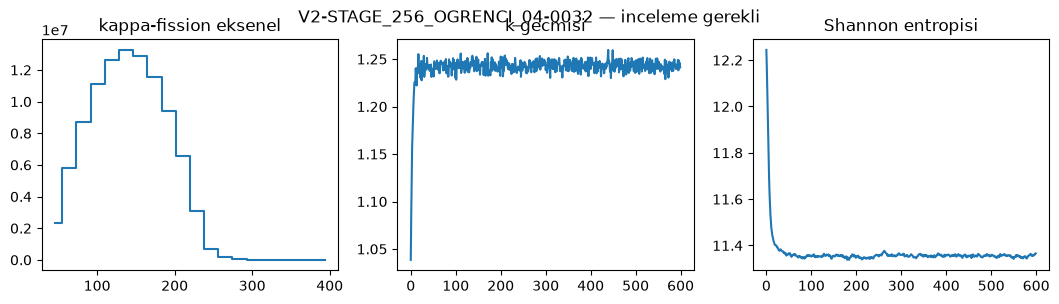

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import json, sys
PACKAGE = Path.cwd().resolve()
PROJECT = next(p for p in (PACKAGE, *PACKAGE.parents) if (p / "src/reactor_pipeline/v2_students.py").is_file())
sys.path.insert(0, str(PROJECT / "src"))
from reactor_pipeline import v2_student_runner, v2_students
assert PACKAGE.name == "v2_stage_256_ogrenci_04_beavrs_v2_pilot_scope_v1"
info = v2_students.verify_package(PACKAGE, require_approval=False)
saved = v2_student_runner.saved_results(PACKAGE)
print("Grup:", saved["group"]["state"], "| completed fiziksel kabul degildir")
rows = []
for case in saved["cases"]:
    summary = case["summary"] or {}
    k = summary.get("k_effective", {})
    manifest_case = next(x for x in v2_students._read(PACKAGE / "manifest.json")["experiments"]
                         if x["experiment_id"] == case["experiment_id"])
    rows.append({"experiment_id": case["experiment_id"],
                 "scenario_id": case["scenario_id"], "state": case["state"],
                 "controls": manifest_case["controls"], "calculation": manifest_case["calculation"],
                 "k": k.get("mean"), "MC_standard_error": k.get("mc_standard_error"),
                 "duration_s": summary.get("duration", {}).get("value"),
                 "fields_npz": str(Path(case["attempt"]) / "fields.npz") if case["attempt"] else None,
                 "summary_json": str(Path(case["attempt"]) / "summary.json") if case["attempt"] else None,
                 "physical_acceptance": case["physical_acceptance"],
                 "statistical_convergence": case["statistical_convergence"]})
display(pd.DataFrame(rows))
for case in saved["cases"]:
    if case["state"] != "completed":
        continue
    with np.load(Path(case["attempt"]) / "fields.npz", allow_pickle=False) as fields:
        z = fields["z_edges_cm"]
        axial = fields["kappa_fission_mean"].sum(axis=(1, 2))
        k_history = fields["k_generation"].copy()
        entropy = fields["shannon_entropy"].copy()
    fig, axes = plt.subplots(1, 3, figsize=(13, 3))
    axes[0].step((z[:-1]+z[1:])/2, axial, where="mid")
    axes[0].set_title("kappa-fission eksenel")
    axes[1].plot(k_history); axes[1].set_title("k gecmisi")
    axes[2].plot(entropy); axes[2].set_title("Shannon entropisi")
    fig.suptitle(case["experiment_id"] + " — inceleme gerekli")
    display(fig)
    plt.close(fig)


## Teslim — hesap başlatmaz
Tamamlanan koşular için WSL terminalinde: `python scripts/v2_transfer.py export student_packages/v2_students_portable_v1/stage_256/ogrenci_04/v2_stage_256_ogrenci_04_beavrs_v2_pilot_scope_v1 deliveries/v2_stage_256_ogrenci_04_beavrs_v2_pilot_scope_v1.zip`. Durum `completed` olmadan teslim tam sayılmaz; varsayılan ZIP statepoint içermez.
